# 04 · Clean

`python -m discovery preprocess` runs the rules in `src/discovery/preprocess/pipeline.py`, in this order, and logs what each one removed or changed:

1. forks · 2. archived · 3. no README **and** no description · 4. clean the README · 5. cap at 20,000 characters · 6. non-English · 7. bot contributors · 8. missing values → "not specified" · 9. duplicates

This notebook runs the same function, then checks the log adds up and reads cleaned READMEs next to the originals.

In [1]:
%load_ext autoreload
%autoreload 2

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from discovery.collect.crawler import iter_jsonl, load_plan
from discovery.config import BACKEND, PATHS, SEED, load_config, set_seed

set_seed()
cfg = load_config()
RAW = PATHS["raw"]
plan = load_plan(BACKEND / "config" / "slices.csv")
print(f"{len(plan)} search pieces | planned take {plan['take'].sum():,} | raw folder {RAW.relative_to(BACKEND)}")

452 search pieces | planned take 11,421 | raw folder data/raw


In [2]:
from discovery.preprocess.pipeline import build_corpus

corpus, log = build_corpus(RAW, PATHS["processed"] / "corpus.parquet", cfg)
log

/Users/user/Documents/Y4/IR/open-source-discovery-engine/backend/src/discovery/preprocess/readme.py:61: XMLParsedAsHTMLWarning: It looks like you're using an HTML parser to parse an XML document.

Assuming this really is an XML document, what you're doing might work, but you should know that using an XML parser will be more reliable. To parse this document as XML, make sure you have the Python package 'lxml' installed, and pass the keyword argument `features="xml"` into the BeautifulSoup constructor.

If you want or need to use an HTML parser on this document, you can make this warning go away by filtering it. To do that, run this code before calling the BeautifulSoup constructor:

    from bs4 import XMLParsedAsHTMLWarning
    import warnings

    warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

  soup = BeautifulSoup(markdown.markdown(t, extensions=["tables"]), "html.parser")


,step,rule,before,removed,after,changed,note
0,0,loaded raw records,8657,0,8657,0,
1,1,forks: fork = true,8657,0,8657,0,
2,2,archived,8657,0,8657,0,
3,3,empty: no README and no description,8657,23,8634,0,
4,4,"clean README (badges, images, HTML, code, link...",8634,0,8634,8527,5 READMEs had nothing left but badges/images/c...
5,5,"length cap: first 20,000 characters",8634,0,8634,1296,
6,6,language: stop-word share < 5% (texts under 30...,8634,411,8223,0,
7,7,bots: contributors with type Bot,8223,0,8223,1583,1583 bot entries removed from contributor lists
8,8,"missing values -> ""not specified""",8223,0,8223,5332,"license: 4079, description: 1253; complexity i..."
9,9,duplicates: full_name,8223,0,8223,0,


## 1. Does the log add up?

before 8,657 − removed 434 = 8,223 | after 8,223 | adds up: True


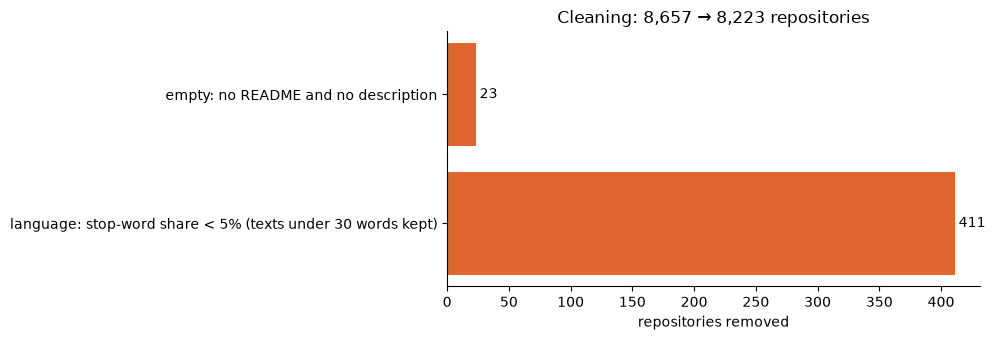

In [3]:
start, end = log["before"].iloc[0], log["after"].iloc[-1]
print(f"before {start:,} − removed {log['removed'].sum():,} = {start - log['removed'].sum():,} | after {end:,} | adds up: {start - log['removed'].sum() == end == len(corpus)}")
fig, ax = plt.subplots(figsize=(10, 3.5))
r = log[log["removed"] > 0]
ax.barh(r["rule"], r["removed"], color="#e0662f")
for i, v in enumerate(r["removed"]):
    ax.text(v, i, f" {v:,}", va="center")
ax.invert_yaxis(); ax.set_xlabel("repositories removed"); ax.set_title(f"Cleaning: {start:,} → {end:,} repositories")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout()

## 2. Read 10 cleaned READMEs next to the originals

In [4]:
raw = {r["full_name"]: r["readme"] for r in iter_jsonl(RAW / "repos.jsonl")}
pick = corpus[corpus["readme"] != ""].sample(10, random_state=SEED)
for row in pick.itertuples():
    print("=" * 100, f"\n{row.full_name}  ·  {row.readme_raw_chars:,} → {len(row.readme):,} characters\n" + "-" * 100)
    left, right = raw[row.full_name][:900].splitlines()[:18], row.readme[:900].splitlines()[:18]
    for a, b in zip(left + [""] * (18 - len(left)), right + [""] * (18 - len(right))):
        print(f"{a[:48]:<50}| {b[:48]}")

snakeUni/note  ·  18,499 → 6,245 characters
----------------------------------------------------------------------------------------------------
# Note And Articles                               | Note And Articles
                                                  | 
记录其他人的优秀的文章以及个人的笔记。每个目录结构都如下，比如 `node 文件夹`        | 记录其他人的优秀的文章以及个人的笔记。每个目录结构都如下，比如
                                                  | 
```ts                                             | 用于记录自己的个人笔记， 用于记录其他人的文章。
├── notes                                         | 
└── technical-articles                            | If you are interested in React Hook, star uni-ho
```                                               | 
                                                  | If you are interested in test, star uni-test
`notes` 用于记录自己的个人笔记，`technical-articles` 用于记录其他人  | 
                                                  | 值得看的大神的博客
> If you are interested in React Hook, star [uni  | 
> If you are interested in test, star [uni-tes

**Check:** the right side keeps the sentences that say what the project does; badges, images, install commands and link URLs are gone. Write down anything that slips through (like emoji codes in Phase 1), fix `clean_readme`, add a test in `tests/test_clean.py`, rerun.

## 3. How much text is left?

median kept: 55% | empty after cleaning: 104 | under 30 words: 433


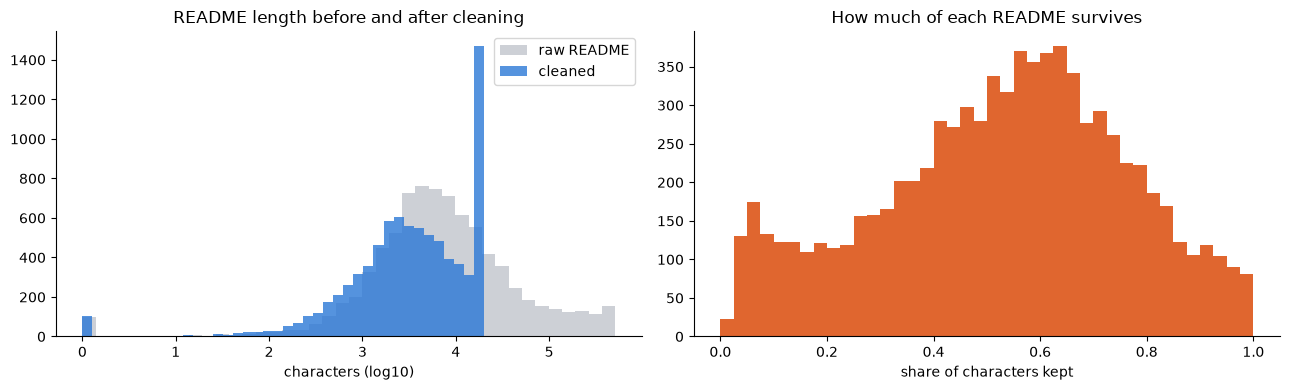

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(np.log10(corpus["readme_raw_chars"].clip(lower=1)), bins=40, alpha=.5, label="raw README", color="#9ca3af")
ax[0].hist(np.log10(corpus["readme"].str.len().clip(lower=1)), bins=40, alpha=.8, label="cleaned", color="#2a78d6")
ax[0].set_xlabel("characters (log10)"); ax[0].legend(); ax[0].set_title("README length before and after cleaning")
ratio = corpus["readme"].str.len() / corpus["readme_raw_chars"].replace(0, np.nan)
ax[1].hist(ratio.dropna(), bins=40, color="#e0662f"); ax[1].set_xlabel("share of characters kept"); ax[1].set_title("How much of each README survives")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
print(f"median kept: {ratio.median():.0%} | empty after cleaning: {(corpus['readme'] == '').sum():,} | under 30 words: {(corpus['words'] < 30).sum():,}")

## 4. The language rule: look at what it dropped

In [6]:
flat = pd.DataFrame([{"full_name": r["full_name"], "readme": r["readme"]} for r in iter_jsonl(RAW / "repos.jsonl")])
dropped = flat[~flat["full_name"].isin(corpus["full_name"])].copy()
from discovery.preprocess.pipeline import english_score
from discovery.preprocess.readme import clean_readme
from nltk.corpus import stopwords
sw = set(stopwords.words("english"))
dropped["clean"] = dropped["readme"].map(clean_readme)
dropped[["share", "words"]] = dropped["clean"].map(lambda t: english_score(t, sw)).tolist()
lang = dropped[(dropped["words"] >= cfg["preprocessing"]["english_min_words"]) & (dropped["share"] < cfg["preprocessing"]["english_min_stopword_share"])]
print(f"dropped as not English: {len(lang):,}")
lang.assign(start=lang["clean"].str.slice(0, 90))[["full_name", "share", "words", "start"]].head(12)

dropped as not English: 399


,full_name,share,words,start
1,0day404/vulnerability-poc,0.025121,2269.0,Awesome-POC\n\n【免责声明】本项目所涉及的技术、思路和工具仅供学习，任何人不得...
11,0xT11/CVE-POC,0.027451,7905.0,PoC in GitHub\n\n2020\n\nCVE-2020-0014\n\ntea9...
18,1937983507/ai-tourism-backend,0.002985,335.0,AI 智能旅游规划助手（后端服务）\n\n访问地址：\n\n欢迎体验智能旅游规划服务！\n\...
26,22Warm-XD/telegram-store-manager,0.009709,206.0,Telegram Store Manager\n\n## Telegram Bot + Mi...
62,AJAXWW/guoapp,0.009464,317.0,红果鉴 / 真果鉴\n\nFlutter 多端独立短剧应用，原名“短剧库 APP”。站源请求...
124,Advanced-Frontend/Daily-Interview-Question,0.036364,55.0,Daily-Interview-Question\n\n加入「前端面试互助群」学习小组，搜索...
125,AdvancedCompiler/AdvancedCompiler,0.006977,430.0,程序性能优化理论与方法 & 深度学习编译器设计\n\n先进编译实验室编著的《程序性能优化理论...
137,AgenciaSeniors/TriciGo,0.033918,855.0,TriciGo\n\nPlataforma de movilidad urbana on-d...
152,Ahmedxsaad/IHEC-Codelab-Hackathon,0.035229,1618.0,🏦 BVMT Trading Assistant - FAIN\n\nPlateforme ...
199,AlmogWer/furniture-e-commerce,0.042735,117.0,Furniture E-Commerce\n\nProject Description\n\...


**If it's wrong:** if English READMEs show up here (lists of commands, feature bullet points with few stop words), lower `english_min_stopword_share` in `config.yaml` a little and rerun. Short READMEs are already safe: anything under 30 words is kept.

## 5. Missing values

In [7]:
pd.Series({c: int((corpus[c] == "not specified").sum()) for c in ("description", "license", "language", "complexity")}, name="not specified").to_frame().T

,description,license,language,complexity
not specified,1253,4079,1324,8223


## What we found

*(fill in after running: the log table, what the 10 READMEs looked like, what slipped through, how many were not English)*